# Lab 4 · Introduction to Random Effects Models
## Falls with major injury in nursing homes

**Maths for Data Science III** · Guided lab: run every cell in order, from top to bottom.

**Dataset:** 800 US nursing homes observed every year from 2017 to 2024 (`nursing_home_panel.csv`), the same dataset as Lab 3. The data are simulated for teaching. They follow the structure of the nursing home data that the Centers for Medicare & Medicaid Services (CMS) publishes on Care Compare.

**Learning objectives.** By the end of this lab you will be able to:

1. Explain how a random effects model differs from a fixed effects model, and what it assumes.
2. Estimate a random effects model with `linearmodels.RandomEffects` and interpret its coefficients, including characteristics that never change within a home.
3. Interpret $\theta$ (theta) and the share of variation due to differences between homes.
4. Use the Hausman test to choose between fixed and random effects.

## The scenario

Falls with major injury (hip fractures, head injuries, dislocations) are among the most serious adverse events in nursing homes. For every home, CMS reports `falls_major_injury_pct`: the percentage of long-stay residents who had at least one fall with major injury.

Nurse aides help residents with transfers, walking and toileting, the moments when most falls happen. High staff turnover means more staff who do not yet know each resident's fall risk. Location may matter too: rural homes are often far from hospitals and have smaller pools of experienced staff.

**Research questions:**

1. How do nurse aide time and nursing staff turnover affect the rate of falls with major injury?
2. Do rural homes have more falls with major injury than urban homes with the same staffing?

The second question is about a characteristic that never changes within a home. In Lab 3 we saw that a fixed effects model cannot answer questions like this. A random effects model can.

## From fixed effects to random effects

In Lab 3, the fixed effects model gave every home its own intercept $\alpha_i$ and compared each home only with itself. That removed every constant difference between homes, but it also removed anything we might want to *study* that is constant, such as whether a home is rural.

A **random effects** model writes the home effect differently:

$$\text{Falls}_{it} = \beta_0 + \beta_1 \, \text{AideTime}_{it} + \beta_2 \, \text{Turnover}_{it} + \beta_3 \, \text{Rural}_{i} + u_i + \varepsilon_{it}$$

| Term | Meaning |
|---|---|
| $\beta_0$ | One overall intercept, shared by all homes |
| $\beta_1, \beta_2$ | Effects of variables that change over time (aide time, turnover) |
| $\beta_3$ | Effect of a variable that never changes within a home (rural) |
| $u_i$ | The **random effect** of home $i$: how far this home sits above or below the average, for reasons not in the model |
| $\varepsilon_{it}$ | Everything else that varies from year to year |

Instead of estimating 794 separate intercepts, a random effects model treats the $u_i$ as random draws from a distribution with mean 0, and estimates only **how large** the differences between homes are.

This comes with one key assumption: **the home effect $u_i$ must be unrelated to the explanatory variables.** For example, homes that are unusually fall-prone for reasons we cannot see (building layout, a frailer resident mix) must not also systematically have more or less aide time or turnover.

| | Fixed effects | Random effects |
|---|---|---|
| Home differences | One intercept per home, $\alpha_i$ | A random home effect $u_i$ with an estimated variance |
| Variation used | Within homes only | Within and between homes |
| Characteristics that never change (rural, ownership) | Cannot be estimated | Can be estimated |
| Assumption about home differences | None: they may be related to staffing | Unrelated to the explanatory variables |
| Precision | Lower | Higher, when the assumption holds |

*For clinicians:* in clinical research the same model is usually called a **random-intercept** (multilevel or mixed) model, with patients nested in hospitals instead of years nested in homes.

## 1. Load the data

`linearmodels` is a Python package for panel data models. Install it once; you can skip this cell if it is already installed.

In [1]:
%pip install -q linearmodels


[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: /Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from linearmodels.panel import PanelOLS, RandomEffects, compare

In [3]:
url = "https://raw.githubusercontent.com/thousandoaks/Maths4DS-III/refs/heads/main/datasets/nursing_home_panel.csv"
df = pd.read_csv(url)
df.shape

(6191, 19)

The columns used in this lab:

| Column | Meaning |
|---|---|
| `facility_id` | Home identifier (the unit $i$) |
| `year` | Calendar year (the period $t$) |
| `falls_major_injury_pct` | % of long-stay residents with at least one fall with major injury (our **outcome**) |
| `cna_hprd` | Nurse aide hours per resident per day |
| `nurse_turnover_pct` | % of nursing staff who left the home during the year |
| `rural` | 1 if the home is in a rural county, 0 if urban (never changes) |
| `ownership_type` | For profit, Non profit or Government (never changes) |

## 2. Prepare the panel

CMS does not report the falls rate for homes with too few residents, so we drop those rows. We also create a 0/1 indicator for for-profit ownership.

As in Lab 3, `linearmodels` needs a two-level index: **entity first, time second**. This time we add `drop=False`, which keeps `year` as an ordinary column as well, so we can use it in a formula later.

In [4]:
df = df.dropna(subset=["falls_major_injury_pct"])
df["for_profit"] = (df["ownership_type"] == "For profit").astype(int)

panel = df.set_index(["facility_id", "year"], drop=False)

print("Home-years:", len(panel))
print("Homes:     ", df["facility_id"].nunique())

Home-years: 6110
Homes:      794


## 3. Describe the data

Summary statistics for the outcome and the two staffing variables, over all home-years:

In [5]:
cols = ["falls_major_injury_pct", "cna_hprd", "nurse_turnover_pct"]
df[cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
falls_major_injury_pct,6110.0,3.54,1.32,0.00,2.62,3.54,4.45,8.02
cna_hprd,6110.0,2.23,0.30,1.26,2.02,2.22,2.43,3.39
nurse_turnover_pct,6110.0,53.84,11.07,12.50,46.30,53.90,61.40,93.80


**Interpretation.**

- **Falls with major injury:** in the average home-year, 3.5% of long-stay residents had a fall with major injury. Half of all home-years fall between 2.6% and 4.5%, and the highest rate is 8.0%.
- **Nurse aide time:** 2.23 hours per resident per day on average, ranging from 1.3 to 3.4 hours.
- **Staff turnover:** on average, 54% of a home's nursing staff left during the year. Some homes lost fewer than 15%, others over 90%.

The two characteristics that never change are best counted per home, not per home-year:

In [6]:
homes = df.groupby("facility_id")[["rural", "ownership_type"]].first()

print(homes["rural"].value_counts().rename({0: "Urban", 1: "Rural"}), "\n")
print(homes["ownership_type"].value_counts())

rural
Urban    593
Rural    201
Name: count, dtype: int64 

ownership_type
For profit    534
Non profit    201
Government     59
Name: count, dtype: int64


About a quarter of the homes (201 of 794) are rural. Two-thirds are for-profit.

Now compare the falls rate in rural and urban homes, year by year:

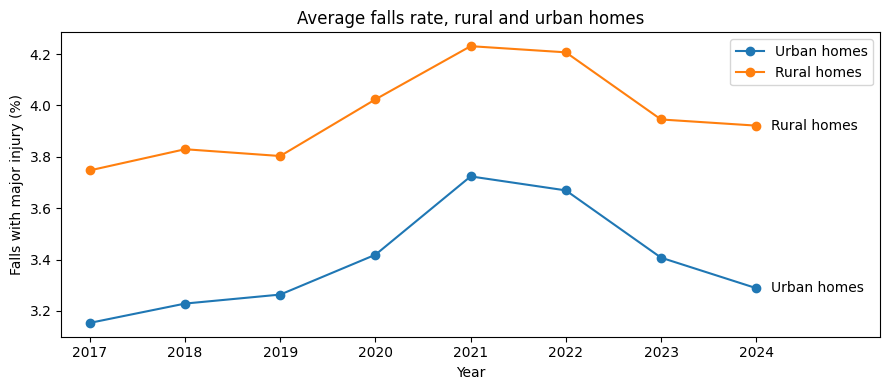

In [7]:
by_area = df.groupby(["year", "rural"])["falls_major_injury_pct"].mean().unstack()
by_area.columns = ["Urban homes", "Rural homes"]

ax = by_area.plot(marker="o", figsize=(9, 4))
for name in by_area.columns:
    ax.text(by_area.index[-1] + 0.15, by_area[name].iloc[-1], name, va="center")
ax.set_xlim(by_area.index[0] - 0.3, by_area.index[-1] + 1.3)
ax.set_xticks(by_area.index)
ax.set_xlabel("Year")
ax.set_ylabel("Falls with major injury (%)")
ax.set_title("Average falls rate, rural and urban homes")
plt.tight_layout()
plt.show()

**How to read the plot**

- Rural homes have a higher falls rate than urban homes **in every year**, by roughly half a percentage point.
- Both groups rose during the COVID-19 years (2020 to 2022) and then came back down, so year effects will be needed.
- A home's rural status never changes, so this gap exists only *between* homes. A fixed effects model throws away all between-home differences and cannot estimate it.

## 4. Fixed effects as a benchmark

Start with the two-way fixed effects model from Lab 3, with home and year effects and standard errors clustered by home. It will be our benchmark.

In [9]:
fe = PanelOLS.from_formula(
    "falls_major_injury_pct ~ cna_hprd + nurse_turnover_pct + EntityEffects + TimeEffects",
    data=panel,
).fit(cov_type="clustered", cluster_entity=True)
print(fe)

                            PanelOLS Estimation Summary                             
Dep. Variable:     falls_major_injury_pct   R-squared:                        0.0161
Estimator:                       PanelOLS   R-squared (Between):              0.0499
No. Observations:                    6110   R-squared (Within):               0.0504
Date:                    Wed, Oct 28 2026   R-squared (Overall):              0.0491
Time:                            20:03:08   Log-likelihood                   -7581.1
Cov. Estimator:                 Clustered                                           
                                            F-statistic:                      43.406
Entities:                             794   P-value                           0.0000
Avg Obs:                           7.6952   Distribution:                  F(2,5307)
Min Obs:                           1.0000                                           
Max Obs:                           8.0000   F-statistic (robust):

**Interpretation.**

- **`cna_hprd` = −0.41:** in years when a home has one more aide hour per resident per day than usual, its falls rate is 0.41 points lower (SE 0.12; 95% CI −0.65 to −0.18).
- **`nurse_turnover_pct` = 0.019:** in years when a home's turnover is 10 points higher than usual, its falls rate is about 0.19 points higher.
- `rural` is not in this model: as we saw in Lab 3, fixed effects absorb any characteristic that never changes within a home.

## 5. The random effects model

Three notes on the code:

- `1 +` adds the overall intercept $\beta_0$. The home effects $u_i$ are random deviations around it.
- `RandomEffects` has no `TimeEffects` option, so we add the year effects ourselves with `C(year)`: one 0/1 dummy per year, with 2017 as the reference year.
- `rural` and `for_profit` can now enter the model directly.

In [10]:
re_formula = (
    "falls_major_injury_pct ~ 1 + cna_hprd + nurse_turnover_pct"
    " + rural + for_profit + C(year)"
)
re = RandomEffects.from_formula(re_formula, data=panel).fit(
    cov_type="clustered", cluster_entity=True
)
print(re)

                          RandomEffects Estimation Summary                          
Dep. Variable:     falls_major_injury_pct   R-squared:                        0.0813
Estimator:                  RandomEffects   R-squared (Between):              0.1368
No. Observations:                    6110   R-squared (Within):               0.0610
Date:                    Wed, Oct 28 2026   R-squared (Overall):              0.1049
Time:                            20:03:08   Log-likelihood                   -8002.8
Cov. Estimator:                 Clustered                                           
                                            F-statistic:                      49.049
Entities:                             794   P-value                           0.0000
Avg Obs:                           7.6952   Distribution:                 F(11,6098)
Min Obs:                           1.0000                                           
Max Obs:                           8.0000   F-statistic (robust):

**Interpretation.**

- **`cna_hprd` = −0.37:** one more aide hour per resident per day goes with a falls rate 0.37 points lower (SE 0.08; 95% CI −0.54 to −0.21). In practical terms: raising aide time by half an hour per resident per day (five extra 8-hour aide shifts a day in an 80-resident home) lowers the falls rate by about 0.19 points.
- **`nurse_turnover_pct` = 0.019:** 10 points more turnover goes with a falls rate about 0.19 points higher (95% CI 0.016 to 0.023 per point).
- **`rural` = 0.50:** rural homes have a falls rate 0.50 points higher than urban homes with the same staffing, turnover and ownership (95% CI 0.35 to 0.66). That is roughly 15% more falls with major injury than in urban homes.
- **`for_profit` = 0.13:** for-profit homes are not clearly different from other homes (p = 0.088; the 95% CI runs from −0.02 to 0.27).
- **Year dummies:** compared with 2017, the falls rate was highest in 2021 (+0.30 points), in line with the plot in Section 3.

Note how close the staffing coefficients are to the fixed effects benchmark (−0.37 against −0.41, and 0.019 in both).

## 7. Fixed or random effects? The Hausman test

Put the two models side by side:

In [13]:
print(compare({"Fixed effects": fe, "Random effects": re}, precision="std_errors"))

                               Model Comparison                              
                                     Fixed effects             Random effects
-----------------------------------------------------------------------------
Dep. Variable               falls_major_injury_pct     falls_major_injury_pct
Estimator                                 PanelOLS              RandomEffects
No. Observations                              6110                       6110
Cov. Est.                                Clustered                  Clustered
R-squared                                   0.0161                     0.0813
R-Squared (Within)                          0.0504                     0.0610
R-Squared (Between)                         0.0499                     0.1368
R-Squared (Overall)                         0.0491                     0.1049
F-statistic                                 43.406                     49.049
P-value (F-stat)                            0.0000              

The same comparison as a forest plot, for the two staffing variables:

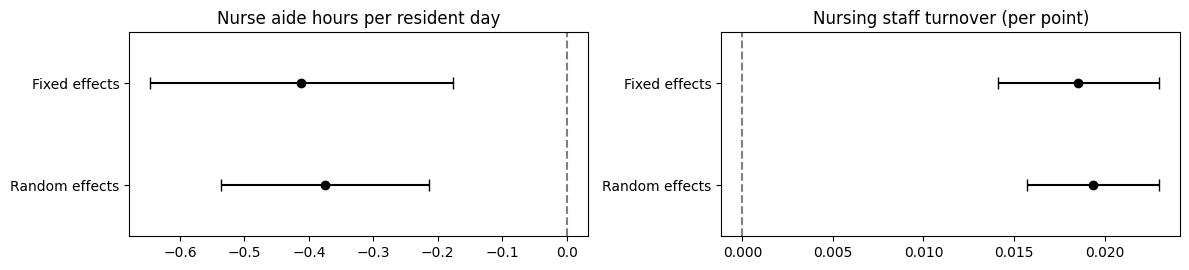

In [14]:
models = {"Fixed effects": fe, "Random effects": re}
labels = {"cna_hprd": "Nurse aide hours per resident day",
          "nurse_turnover_pct": "Nursing staff turnover (per point)"}

fig, axes = plt.subplots(1, 2, figsize=(12, 2.8))
for ax, (var, label) in zip(axes, labels.items()):
    est = np.array([m.params[var] for m in models.values()])
    lower = np.array([m.conf_int().loc[var, "lower"] for m in models.values()])
    upper = np.array([m.conf_int().loc[var, "upper"] for m in models.values()])
    y = np.arange(len(models))[::-1]
    ax.errorbar(est, y, xerr=[est - lower, upper - est], fmt="o", color="black", capsize=4)
    ax.axvline(0, color="grey", linestyle="--")
    ax.set_yticks(y, models.keys())
    ax.set_ylim(-0.5, len(models) - 0.5)
    ax.set_title(label)
plt.tight_layout()
plt.show()

**How to read the plot.** For both variables the two estimates are close, and the random effects interval is narrower. For aide time, the random effects standard error is about a third smaller (0.08 against 0.12), because the model also learns from differences between homes.

### The logic of the Hausman test

- If the random effects assumption **holds**, both models are estimating the same thing. Their estimates should be close, and random effects is more precise.
- If it **fails** (the home effects are related to staffing), fixed effects is still right but random effects is biased, and the estimates drift apart.

The Hausman test asks whether the gap between the two sets of estimates is larger than chance alone would produce:

$$H = (b_{FE} - b_{RE})^\top \left[ V_{FE} - V_{RE} \right]^{-1} (b_{FE} - b_{RE}) \;\sim\; \chi^2_k$$

Here $b$ are the coefficients the two models share, $V$ their covariance matrices, and $k$ the number of shared coefficients (here 2).

- **Null hypothesis:** the random effects assumption holds, so use **random effects**.
- **Small p-value** (below 0.05): the estimates differ too much, so use **fixed effects**.

`linearmodels` has no built-in Hausman test, so we compute it ourselves. The classic version uses the conventional (unclustered) standard errors, so we refit both models without clustering for this step:

In [15]:
fe_h = PanelOLS.from_formula(
    "falls_major_injury_pct ~ cna_hprd + nurse_turnover_pct + EntityEffects + TimeEffects",
    data=panel,
).fit()
re_h = RandomEffects.from_formula(re_formula, data=panel).fit()

shared = ["cna_hprd", "nurse_turnover_pct"]
diff = fe_h.params[shared] - re_h.params[shared]
var_diff = fe_h.cov.loc[shared, shared] - re_h.cov.loc[shared, shared]

H = diff @ np.linalg.inv(var_diff) @ diff
p_value = stats.chi2.sf(H, df=len(shared))

print("Difference FE - RE:")
print(diff.round(4), "\n")
print(f"Hausman statistic H = {H:.2f}, p-value = {p_value:.3f}")

Difference FE - RE:
cna_hprd             -0.0372
nurse_turnover_pct   -0.0008
Name: parameter, dtype: float64 

Hausman statistic H = 1.23, p-value = 0.541


**Interpretation.** $H = 1.23$ with $p = 0.54$: the two models differ by no more than chance would produce, so we **do not reject** the random effects assumption. Random effects is the better model here: it agrees with fixed effects on staffing, is more precise, and answers our second research question about rural homes.

This is not always the outcome. In Lab 3, homes with sicker residents had both more RN time and more pressure ulcers. There the home effect *is* related to staffing, the Hausman test rejects random effects, and fixed effects is the right choice. Run the test before you trust a random effects model.

## 8. Key takeaways

- A **random effects** model treats the differences between homes as random draws. It estimates how large they are rather than one intercept per home.
- Its key assumption is that the home effects are **unrelated to the explanatory variables**. When this holds, random effects uses both within-home and between-home variation, so it is **more precise** than fixed effects and **can estimate characteristics that never change**, such as rural location.
- $\theta$ tells you how much of each home's average the model removes: 0.66 here for homes observed all eight years, compared with 1 for fixed effects.
- About **half** of the unexplained variation in falls with major injury comes from stable differences between homes (ICC = 0.49).
- The **Hausman test** compares fixed and random effects. A large p-value (0.54 here) supports random effects; a small one means you should use fixed effects.
- Results: one more aide hour per resident per day lowers the falls rate by about **0.37 points**; 10 points more staff turnover raises it by about **0.19 points**; rural homes have about **0.5 points** (roughly 15%) more falls with major injury than comparable urban homes; for-profit ownership makes no clear difference.
